# Sequential predictive conformal inference

The residual-based methods take their width from a quantile of past errors, so at
a given horizon step it is a constant. SPCI fits a quantile regressor on the
recent residual history and predicts the next residual's spread instead, so the
width moves with the state the series is in.

## What it does

For each `(series, horizon)` cell, SPCI fits a quantile regressor that predicts
the *next* signed residual from the previous `window_size` residuals — and from
exogenous features, if you supply them. Call its predicted quantile function `Q`.
The interval is

```
[ŷ + Q(beta), ŷ + Q(1 - alpha + beta)]
```

for whichever `beta` in `[0, alpha]` makes it narrowest. That search is the
second idea: an interval of the right coverage need not be centred. When the
residual distribution is skewed, spending more of `alpha` on one tail gives a
tighter interval at the same nominal level, and SPCI searches a grid of
`beta_grid_size` candidates for the best split.

Because `Q` depends on the recent residual history, the width moves with the
data. A run of large errors widens the next interval directly, without waiting
for a controller to notice a miss.

::: {.callout-note}
## Original method

The paper's estimator is a quantile random forest, which is also
this implementation's default.
:::

::: {.callout-important}
## SPCI needs the `spci` extra and costs more than the others

The default `QRFQuantileRegressor` wraps `quantile-forest`:
`pip install conformalforecast[spci]`. SPCI is also the one sanctioned exception
to the package's no-per-cell-loops rule — it fits one regressor per
`(series, horizon)` cell, so an 8-series panel at horizon 24 means 192 forests.
Keep the grid small, or raise `refit_every` so the regressors are refitted less
often.
:::

## Worked example

SPCI is formulated for sequential one-step-ahead prediction, so that is what this
page does: forecast one hour ahead on a single M4 hourly series, and stream three
days through the method an observation at a time.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

from conformalforecast import SequentialPredictiveConformalInference, SplitConformal
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import spci_state

SEASON, ALPHA, WINDOW = 24, 0.1, 48
N_STREAM = 72  # three days, one hour at a time

full = pd.read_csv("nbs/data/m4_hourly_panel.csv", parse_dates=["ds"])
df = full[full["unique_id"] == "H1"].reset_index(drop=True)
series = df["y"].to_numpy()[None, :]
train_end = series.shape[1] - N_STREAM
train_df = df.iloc[:train_end].reset_index(drop=True)

sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON)], freq="h", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=1, freq="h", model_name="SeasonalNaive"
)

spci = SequentialPredictiveConformalInference(alpha=ALPHA, window_size=WINDOW, refit_every=4)
spci_fitted = spci.calibrate_cv(forecaster, n_windows=150, refit=True)

split_fitted = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=150, refit=True)

state = spci_state(spci_fitted)
for key in ("window_size", "n_observations", "n_regressors", "regressor_class", "refit_every"):
    print(f"{key:18s} {state[key]}")

window_size        48
n_observations     150
n_regressors       1
regressor_class    QRFQuantileRegressor
refit_every        4


`n_regressors` is the `(series × horizon)` grid — one series, one horizon step,
so one forest. Each saw `n_observations` residuals and keeps the last
`window_size` of them as its feature vector.

::: {.callout-note}
## SPCI needs a longer calibration set than the others

The minimum is `max(window_size + 1, ceil(1/alpha))` effective residuals per
series, not just `ceil(1/alpha)` — the regressor needs a full window before it
can predict anything. That is why this page asks for 150 cross-validation windows
where the split conformal page needed 24.
:::

In [ ]:
def stream(fitted, *, online=True):
    """Roll one hour at a time, recording the interval and whether it covered."""
    lower, upper, covered = [], [], []
    for t in range(train_end, series.shape[1]):
        prediction = fitted.predict(series[:, :t])
        lo, hi = prediction.interval[0, 0, 0]
        lower.append(lo)
        upper.append(hi)
        covered.append(lo <= series[0, t] <= hi)
        if online:
            fitted.update(prediction.point, series[:, t : t + 1][:, None, :])
    return {"lower": np.array(lower), "upper": np.array(upper), "covered": np.array(covered)}


runs = {"SPCI": stream(spci_fitted), "split conformal": stream(split_fitted, online=False)}

for name, run in runs.items():
    width = run["upper"] - run["lower"]
    print(
        f"{name:18s} coverage {run['covered'].mean():6.1%}   "
        f"mean width {width.mean():7.1f}   "
        f"width range {width.min():6.1f} - {width.max():6.1f}"
    )

SPCI               coverage  81.9%   mean width    55.1   width range   24.0 -  109.3
split conformal    coverage  79.2%   mean width   122.0   width range  122.0 -  122.0


## Width that moves

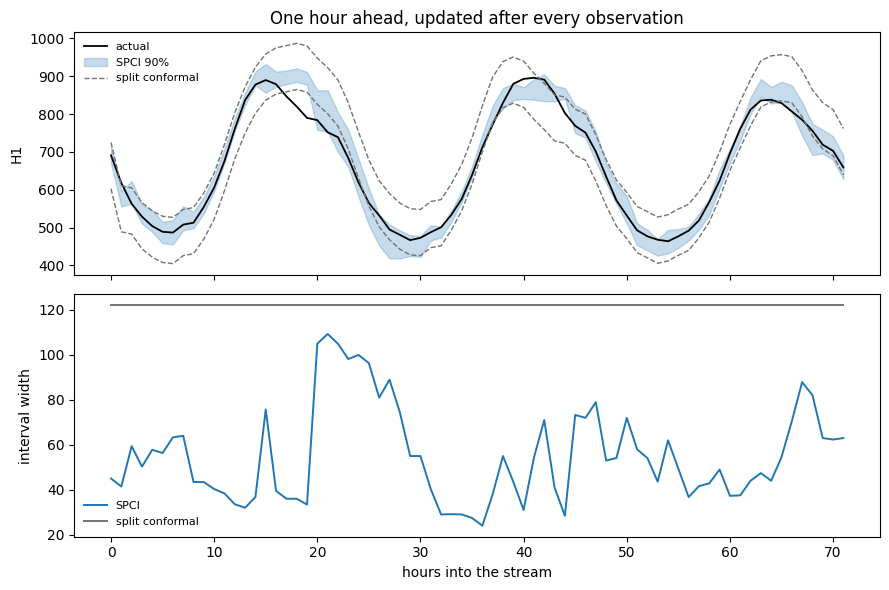

In [ ]:
hours = np.arange(N_STREAM)
truth = series[0, train_end:]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

top.plot(hours, truth, color="k", lw=1.3, label="actual")
top.fill_between(
    hours,
    runs["SPCI"]["lower"],
    runs["SPCI"]["upper"],
    color="C0",
    alpha=0.25,
    label="SPCI 90%",
)
top.plot(
    hours, runs["split conformal"]["lower"], color="0.45", lw=1, ls="--", label="split conformal"
)
top.plot(hours, runs["split conformal"]["upper"], color="0.45", lw=1, ls="--")
top.set_ylabel("H1")
top.set_title("One hour ahead, updated after every observation")
top.legend(fontsize=8, frameon=False, loc="upper left")

for name, colour in [("SPCI", "C0"), ("split conformal", "0.45")]:
    bottom.plot(hours, runs[name]["upper"] - runs[name]["lower"], color=colour, lw=1.4, label=name)
bottom.set_ylabel("interval width")
bottom.set_xlabel("hours into the stream")
bottom.legend(fontsize=8, frameon=False)
fig.tight_layout()

The bottom panel is the whole argument. Split conformal draws a horizontal line —
its width is a constant of the fitted state, identical at 3 a.m. and at the
evening peak. SPCI's width rises and falls, because the residuals it regresses on
do.

Both are valid intervals. Only one of them is *informative*: a width that carries
a signal tells you something the point forecast does not.

Here that pays on both axes at once. SPCI covered 82% of the stream at a mean
width of 55, while split conformal covered 79% at a constant width of 122 — less
than half the width for slightly better coverage. Note that neither reached the
90% target over these particular 72 hours; three days is a short measurement, and
the widest SPCI intervals cluster exactly where the series ramps.

::: {.callout-warning}
## Measure SPCI's coverage before you trust it

SPCI's validity is asymptotic and conditional on the residual model being
reasonable, which is a much weaker footing than split conformal's finite-sample
guarantee. Two consequences show up in practice:

- Even on well-behaved data it tends to land a few points **below** nominal. The
  package's own coverage test (`tests/unit/methods/test_spci.py`) allows a
  tolerance of 0.08 around the target for exactly this reason.
- At **multi-step horizons on real series** the gap can be much larger. On this
  same panel at horizon 6, SPCI covers around 65% against a 90% target while
  split conformal holds 90% — the quantile forest is asked to extrapolate to
  residual magnitudes it never saw in training, and tree models cannot
  extrapolate.

Neither is a reason to avoid SPCI; both are reasons to run
[`evaluate`](../capabilities/diagnostics) on your own data and horizon before
shipping it, rather than assuming the guarantee carries over.
:::

## When not to use it

- **You cannot install the extra.** SPCI is the only method with a third-party
  dependency.
- **Your grid is large.** `n_series × horizon` regressors, refitted as you go. A
  100-series panel at horizon 48 is 4 800 forests — consider [CQR](cqr), which
  gets varying width from a model you already fit.
- **Your calibration set is short.** `window_size + 1` residuals per series is a
  real constraint, and the default `window_size` is 100.
- **You need the classical guarantee, or a long horizon.** [Split
  conformal](split) is finite-sample and assumption-light; on this data it is
  also the one that holds its coverage at horizon 6.

## References
X. Chen and X. Yao, “Sequential Predictive Conformal Inference for Time Series,” arXiv.org, 2022. https://arxiv.org/abs/2212.03463.

## Next

- [Methods overview](index) — the decision guide, now that you have seen all six.
- [Exogenous features](../capabilities/exogenous) — SPCI is the method that can
  actually use them.
- [Diagnostics](../capabilities/diagnostics) — how to run the measurement the
  callout above asks for.